In [22]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import human_ET_model, simulate_dipole, jones_2009_model

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology
import decimal

# import pandas as pd
from scipy import signal
import sys
from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/compare_jones2009'

In [ ]:
cols = np.array(([67, 104, 158], [164,30,79], [117,112,179], [231,41,138], [102,166,30]))/255

def stim_dpl(net, stim_cell='L5_pyramidal'):

    window_len, scaling_factor = 30, 1

    net.clear_connectivity()

    net.set_cell_positions(inplane_distance=30.)

    depths = list(list(range(-100,2400,200)))
    electrode_pos = [(135, 135, dep) for dep in depths]

    net.add_electrode_array('probe1', electrode_pos)

    ampl = 2.5
    t0 = 20

    for i in range(1):
        net.add_tonic_bias(cell_type=stim_cell,section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+20)

    dpl = simulate_dipole(net, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='none')
    smooth_dpl = dpl[0].copy()
    smooth_dpl.smooth(window_len).scale(scaling_factor)

    return net, dpl, smooth_dpl


def plot_dpl_l5(net, dpl, smooth_dpl, axs, gid, row_idx):

    timevec = net.cell_response.times

    v = net.cell_response.vsec[0][gid]['soma']
    v_apcl = net.cell_response.vsec[0][gid]['apical_tuft']
    axs[row_idx,0].plot(timevec, v, color=cols[0], linewidth=2, alpha=0.5)
    axs[row_idx,0].plot(timevec, v_apcl, color=cols[0], linewidth=2)
    clamp = np.zeros_like(v)
    t0 = np.argmin(np.abs(timevec - 20))
    t1 = np.argmin(np.abs(timevec - 40))
    clamp[t0:t1] = 2.5
    axs[row_idx,0].plot(timevec, clamp-85, color='r', linewidth=1., label='clamp')

    axs[row_idx,0].set_ylabel('membrane potential $\mu V$')
    axs[row_idx,0].set_ylim([-90, 50])
    axs[row_idx,0].set_yticks([-70,0, 50])
    axs[row_idx,0].spines['top'].set_visible(False)
    axs[row_idx,0].spines['right'].set_visible(False)

    ca_soma = net.cell_response.ca[0][gid]['soma']

    ca= net.cell_response.ca[0][gid]['apical_tuft']

    axs[row_idx,1].plot(timevec, ca_soma, color=cols[0], linewidth=1.5, alpha=0.5, label='soma')
    axs[row_idx,1].plot(timevec, ca, color=cols[0], linewidth=1.5, label='apical tuft')
    axs[row_idx,1].set_ylabel('calcium concentration (mM)')
    axs[row_idx,1].legend(loc='upper right', fontsize=8)
    axs[row_idx,1].legend()
    axs[row_idx,1].spines['top'].set_visible(False)
    axs[row_idx,1].spines['right'].set_visible(False)

    all_ca = np.concatenate((ca_soma, ca))
    max_ca = np.max(all_ca)
    fractional = str(max_ca*1.05).split('.')[1] 
    decim = sum(1 for digit in fractional if digit == '0')
    axs[row_idx,1].set_ylim([0., np.round(max_ca*1.05, decimals=decim)])
    axs[row_idx,1].set_yticks([0, np.round(max_ca*1.05, decimals=decim)/2, np.round(max_ca*1.05, decimals=decim)])

    # convert dipole to nAm/mm2
    net_dict = net.cell_types['L5_pyramidal'].to_dict()
    basal_plane = np.abs(net_dict['sections']['basal_2']['end_pts'][1][0] - net_dict['sections']['basal_3']['end_pts'][1][0]) * net_dict['sections']['soma']['diam']

    surface_mm2 = basal_plane*1e-6
    axs[row_idx,2].plot(timevec, dpl[0].data['L5']/surface_mm2, label='unsmoothed', color='k', linewidth=2, alpha=0.5)
    axs[row_idx,2].plot(timevec, smooth_dpl.data['L5']/surface_mm2, label='smoothed', color='k', linewidth=2)
    axs[row_idx,2].legend(loc='upper right', fontsize=8)
    axs[row_idx,2].set_title('')
    axs[row_idx,2].set_ylabel('dipole moment ($nAm/mm^2$)')
    axs[row_idx,2].set_ylim([-0.2, 0.3])
    axs[row_idx,2].spines['top'].set_visible(False)
    axs[row_idx,2].spines['right'].set_visible(False)
    for ax in axs[row_idx]:
        ax.set_xlabel('time (s)')

    return axs



def plot_dpl_l23(net, dpl, smooth_dpl, axs, gid, row_idx):

    timevec = net.cell_response.times

    v = net.cell_response.vsec[0][gid]['soma']
    v_apcl = net.cell_response.vsec[0][gid]['apical_tuft']
    axs[row_idx,0].plot(timevec, v, color=cols[1], linewidth=1.5, alpha=0.5, label='soma')
    axs[row_idx,0].plot(timevec, v_apcl, color=cols[1], linewidth=1.5, label='apical tuft')
    axs[row_idx,0].legend()
    axs[row_idx,0].set_ylabel('membrane potential $\mu V$')
    axs[row_idx,0].set_ylim([-90, 60])
    axs[row_idx,0].set_yticks([-70,0, 50])
    axs[row_idx,0].spines['top'].set_visible(False)
    axs[row_idx,0].spines['right'].set_visible(False)
    clamp = np.zeros_like(v)
    t0 = np.argmin(np.abs(timevec - 20))
    t1 = np.argmin(np.abs(timevec - 40))
    clamp[t0:t1] = 2.5
    axs[row_idx,0].plot(timevec, clamp-85, color='r', linewidth=1., label='clamp')
    
    # convert dipole to nAm/mm2
    net_dict = net.cell_types['L2_pyramidal'].to_dict()
    basal_plane = np.abs(net_dict['sections']['basal_2']['end_pts'][1][0] - net_dict['sections']['basal_3']['end_pts'][1][0]) * net_dict['sections']['soma']['diam']

    surface_mm2 = basal_plane*1e-6

    axs[row_idx,1].plot(timevec, dpl[0].data['L2']/surface_mm2, label='unsmoothed', color='k', linewidth=2, alpha=0.5)
    axs[row_idx,1].plot(timevec, smooth_dpl.data['L2']/surface_mm2, label='smoothed', color='k', linewidth=2)
    axs[row_idx,1].legend(loc='upper right', fontsize=8)
    axs[row_idx,1].set_title('')
    axs[row_idx,1].set_ylabel('dipole moment ($nAm/mm^2$)')
    axs[row_idx,1].set_ylim([-0.2, 0.3])
    axs[row_idx,1].spines['top'].set_visible(False)
    axs[row_idx,1].spines['right'].set_visible(False)
    for ax in axs[row_idx]:
        ax.set_xlabel('time (s)')

    return axs

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...


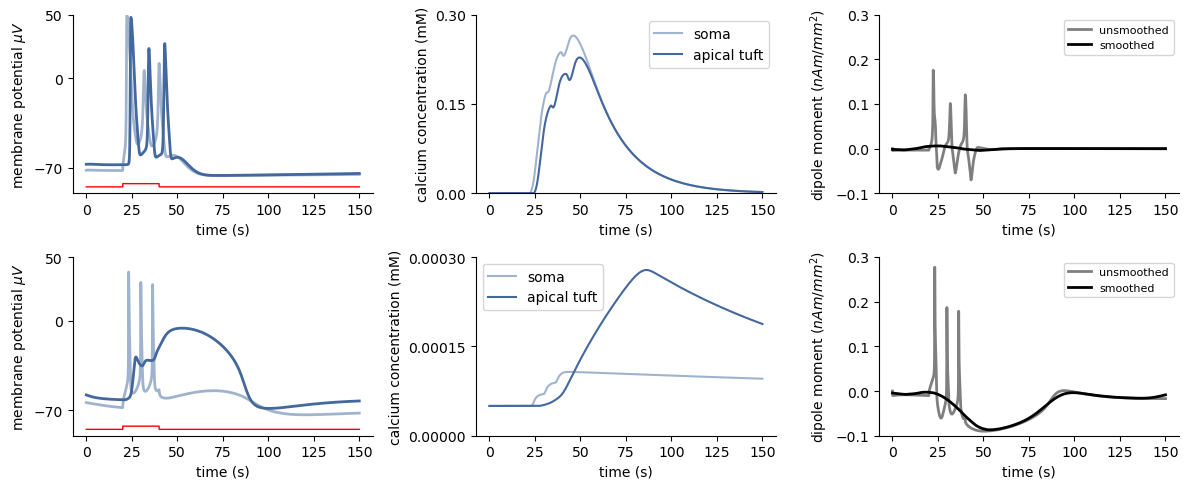

In [24]:
fig, axs = plt.subplots(2,3,figsize=(12,5))

gid = 3

net, dpl, smooth_dpl = stim_dpl(jones_2009_model(mesh_shape=(1,1)), stim_cell='L5_pyramidal')

plot_dpl_l5(net, dpl, smooth_dpl, axs, gid, 0)

net, dpl, smooth_dpl = stim_dpl(human_ET_model(mesh_shape=(1,1)), stim_cell='L5_pyramidal')

plot_dpl_l5(net, dpl, smooth_dpl, axs, gid, 1)

fig.tight_layout()

fig.savefig(os.path.join(pathfig, 'compare_jones2009_new_model_l5.pdf'), dpi=300, bbox_inches='tight')
fig.savefig(os.path.join(pathfig, 'compare_jones2009_new_model_l5.png'), dpi=300, bbox_inches='tight')

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...


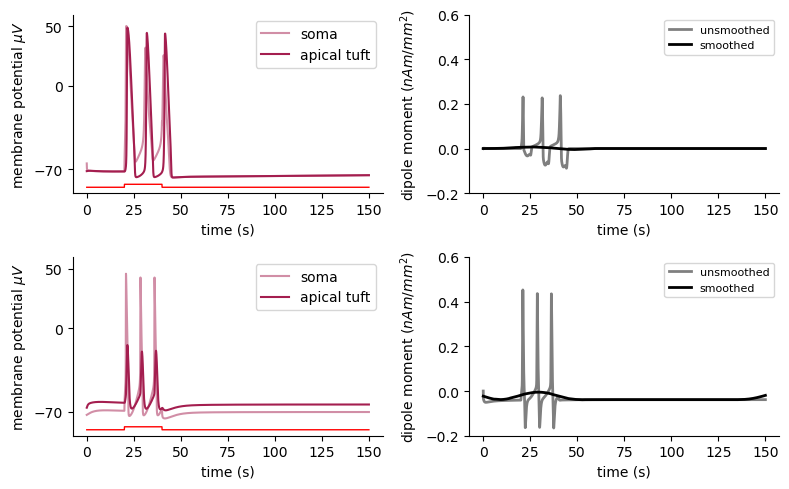

In [25]:
fig, axs = plt.subplots(2,2,figsize=(8,5))
gid = 1

net, dpl, smooth_dpl = stim_dpl(jones_2009_model(mesh_shape=(1,1)), stim_cell='L2_pyramidal')

plot_dpl_l23(net, dpl, smooth_dpl, axs, gid, 0)

net, dpl, smooth_dpl = stim_dpl(human_ET_model(mesh_shape=(1,1)), stim_cell='L2_pyramidal')

plot_dpl_l23(net, dpl, smooth_dpl, axs, gid, 1)

fig.tight_layout()

fig.savefig(os.path.join(pathfig, 'compare_jones2009_new_model_l23.pdf'), dpi=300, bbox_inches='tight')
fig.savefig(os.path.join(pathfig, 'compare_jones2009_new_model_l23.png'), dpi=300, bbox_inches='tight')

In [26]:
pathfig

'/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/compare_jones2009'